In [2]:
import xarray as xr

In [3]:
awra_path = '/g/data/iu04/australian-water-outlook/historical/v1/AWRALv7/processed/values/day/'
filename = 'sm_1948.nc'

sm_ss = xr.open_dataset(awra_path + filename)['sm'].isel(time=slice(0, 10))
sm_ss

<xarray.DataArray 'sm' (time: 10, latitude: 681, longitude: 841)> Size: 23MB
[5727210 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 80B 1948-01-01 1948-01-02 ... 1948-01-10
  * latitude   (latitude) float64 5kB -10.0 -10.05 -10.1 ... -43.9 -43.95 -44.0
  * longitude  (longitude) float64 7kB 112.0 112.0 112.1 ... 153.9 153.9 154.0
Attributes:
    name:           sm
    standard_name:  sm
    long_name:      Total rootzone soil moisture (0-100 cm)
    units:          mm

In [1]:
import xarray as xr
path = '/g/data/w97/mg5624/RF_project/AWRA_SM/daily/'
years = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
for year in years:
    print(year)
    file = f'root_zone_soil_moisture_{year}.nc'

    sm = xr.open_dataset(path+file)
    print(year, 'done')


2017
2017 done
2018
2018 done
2019
2019 done
2020
2020 done
2021
2021 done
2022
2022 done
2023
2023 done
2024
2024 done
2025
2025 done


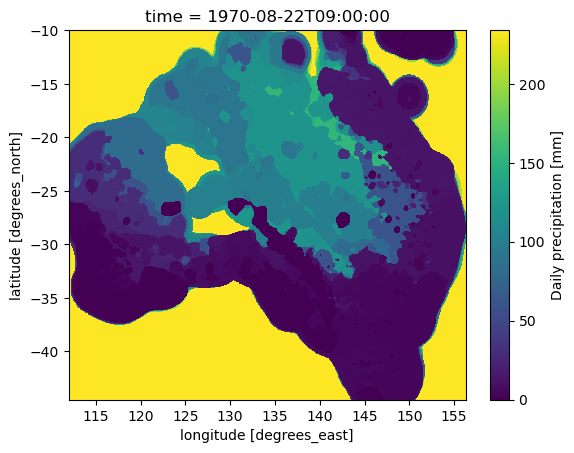

In [6]:
import xarray as xr
path = '/g/data/w97/mg5624/ABS_project/extremes/daily/cdd/'
filename = 'cdd_1970-2025.nc'
da = xr.open_dataset(path+filename)
da.isel(time=233).cdd.plot()

In [9]:
import xarray as xr
FY_path = '/g/data/w97/mg5624/ABS_project/extremes/FY_aggregated/sm_drought_180_intensity/'
filename = 'sm_drought_180_intensity_FY_aggregated_2022-2025.nc'
da = xr.open_dataset(FY_path+filename)
da
# gs_hw = da.growing_seas_sm_drought_180_intensit
# gs_hw

<xarray.Dataset> Size: 36kB
Dimensions:    (time: 1826, lat: 691, lon: 886)
Coordinates:
  * time       (time) datetime64[ns] 15kB NaT NaT NaT NaT ... NaT NaT NaT NaT
  * lat        (lat) float32 3kB -44.5 -44.45 -44.4 ... -10.1 -10.05 -10.0
  * lon        (lon) float32 4kB 112.0 112.1 112.1 112.2 ... 156.1 156.2 156.2
Data variables:
    dayofyear  (time) int64 15kB ...

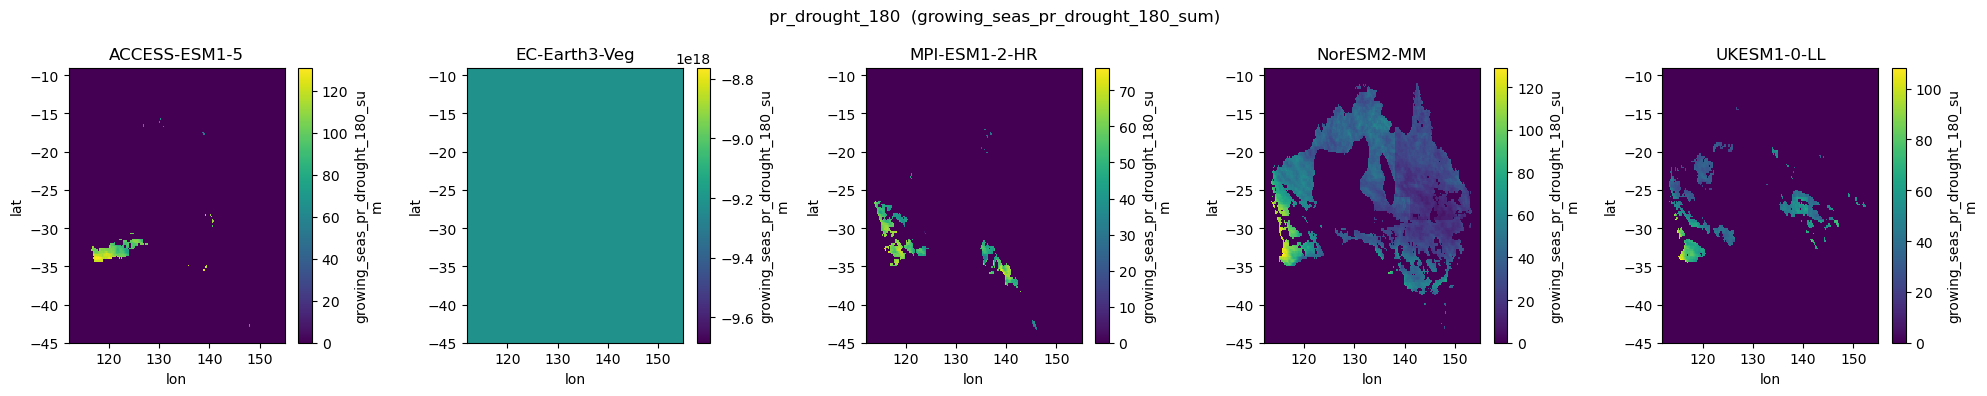

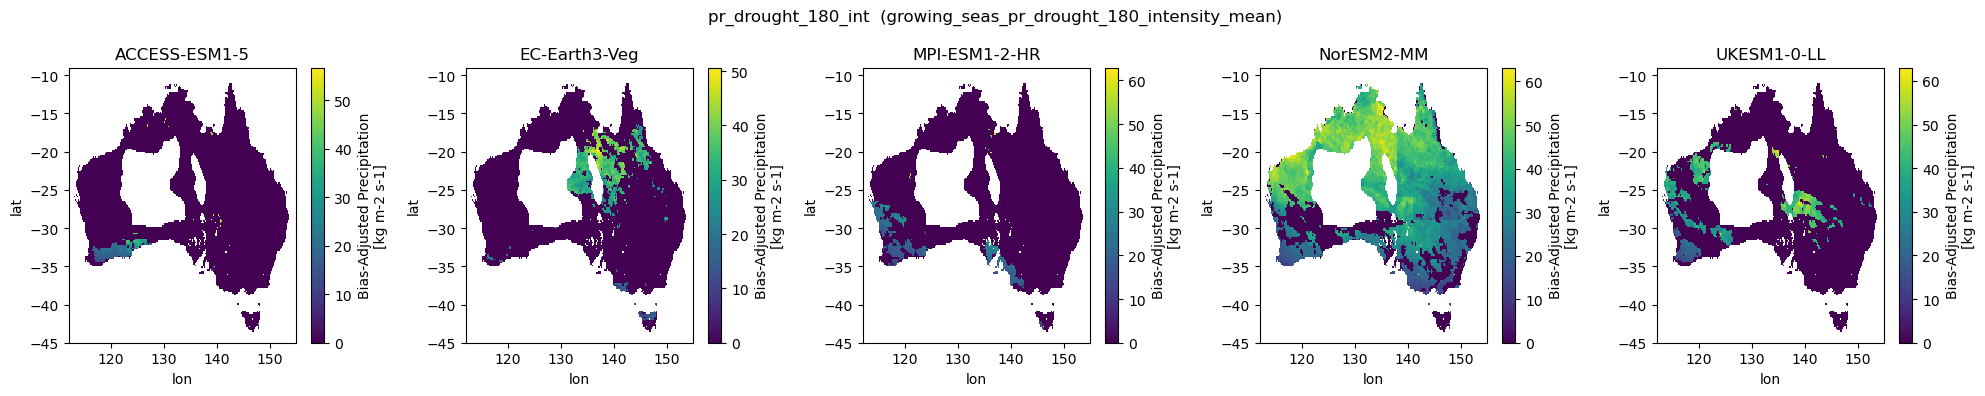

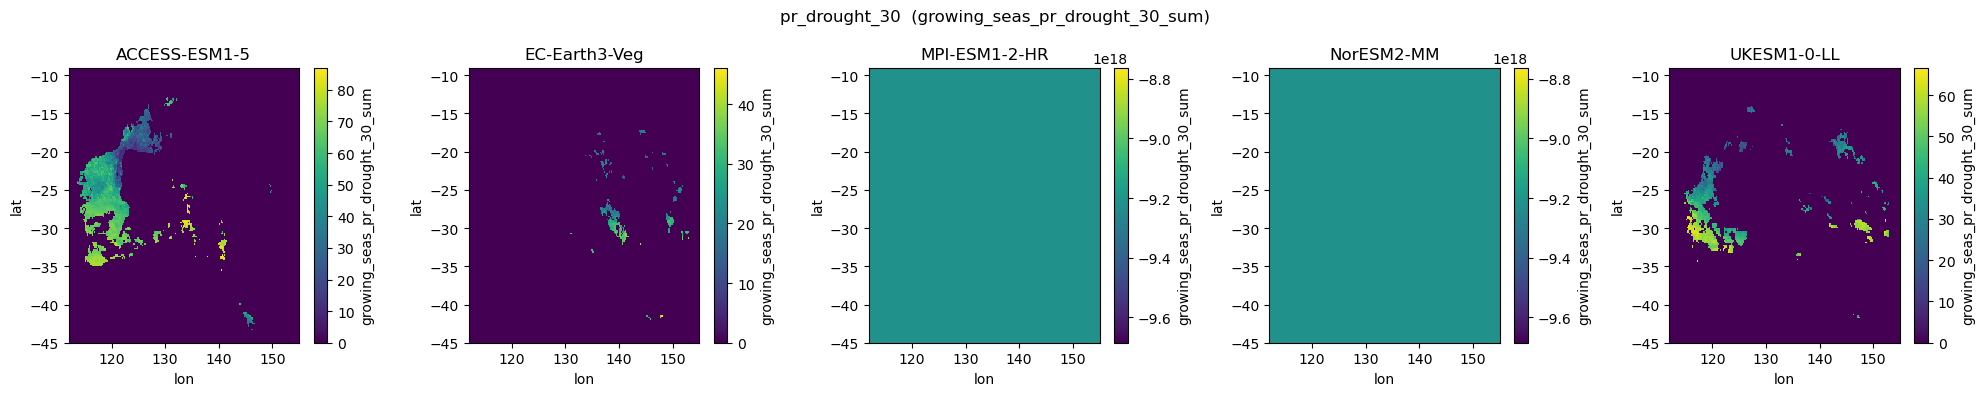

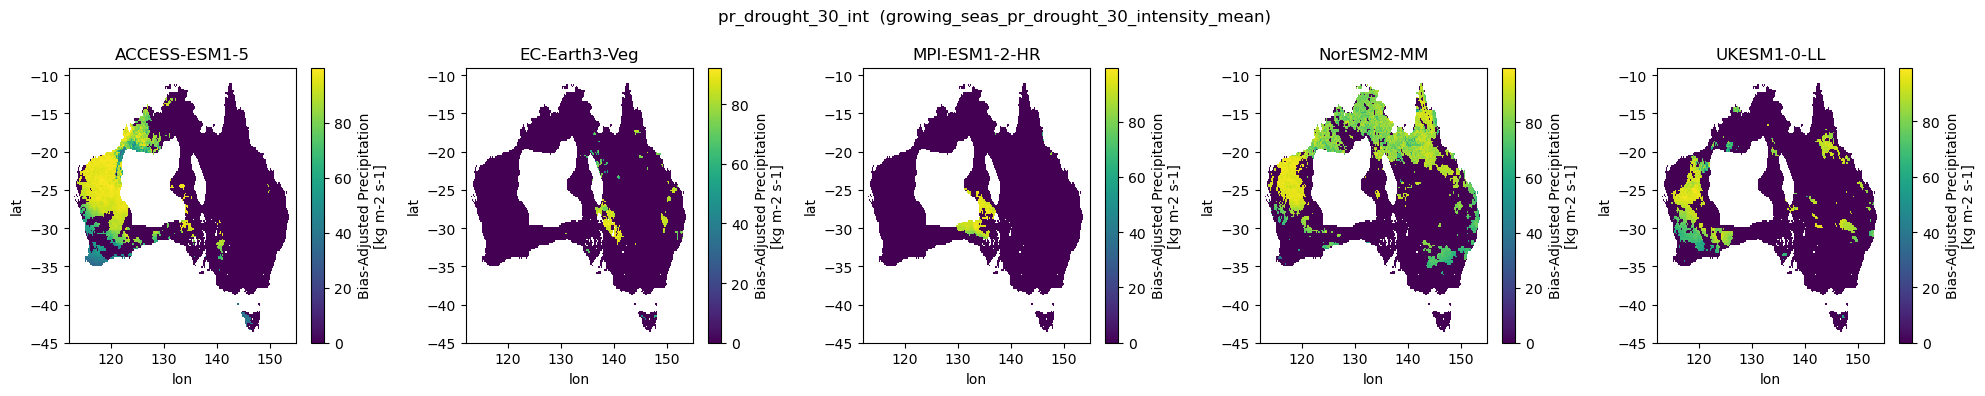

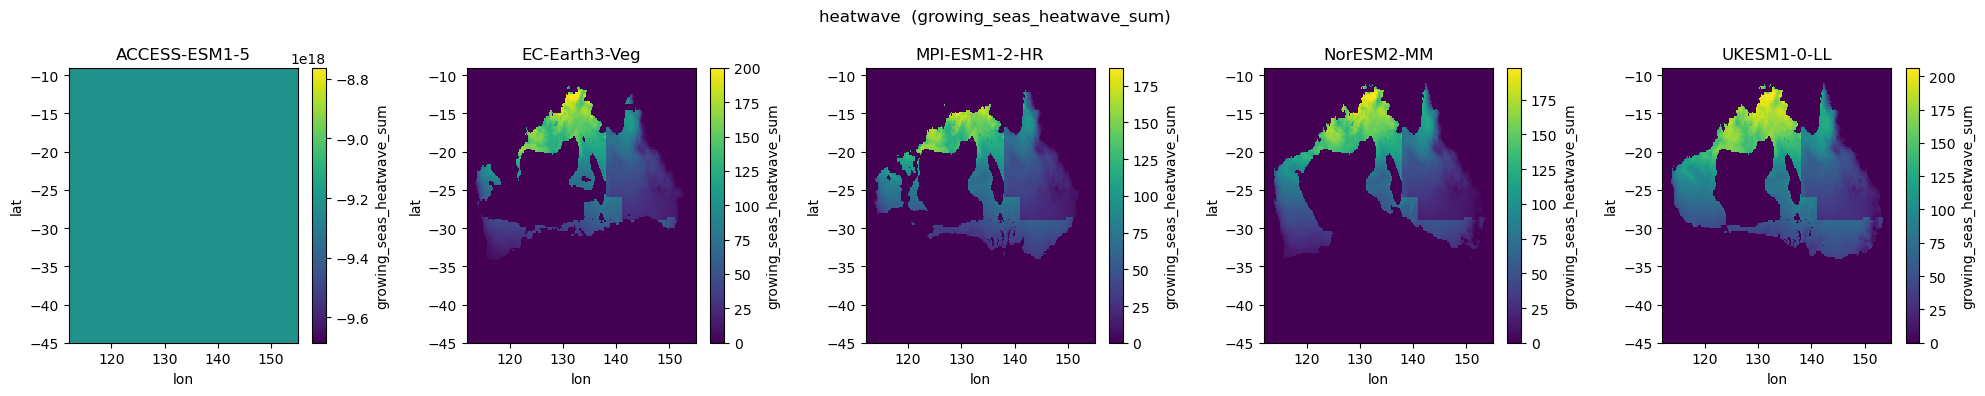

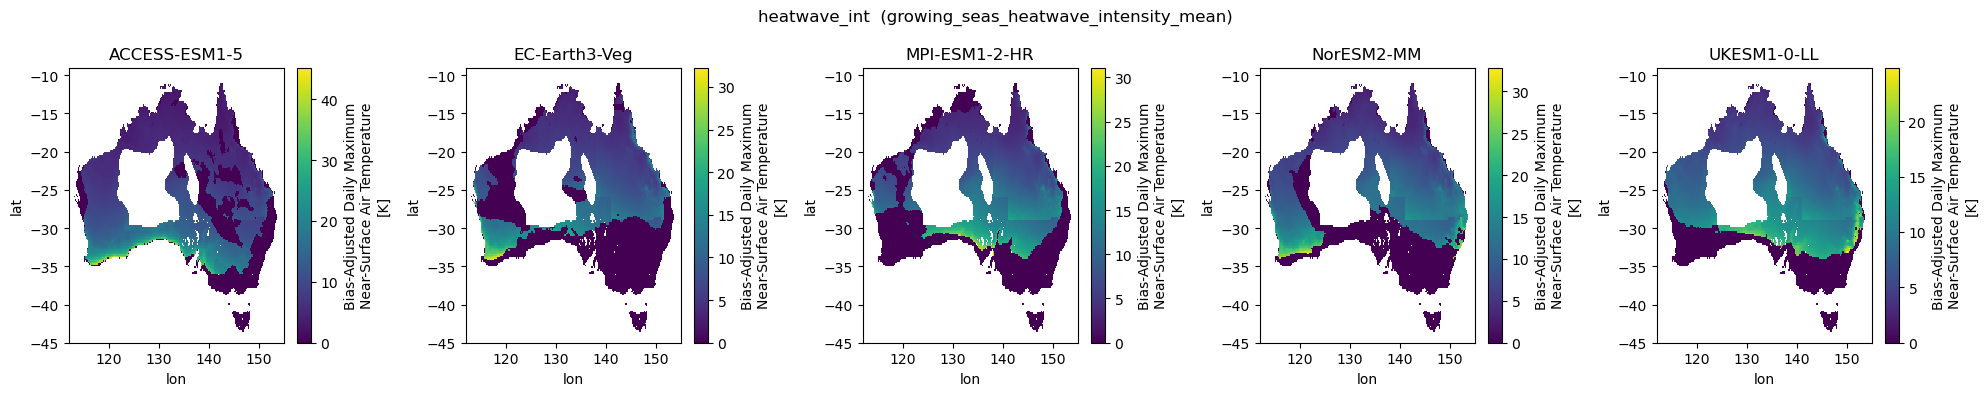

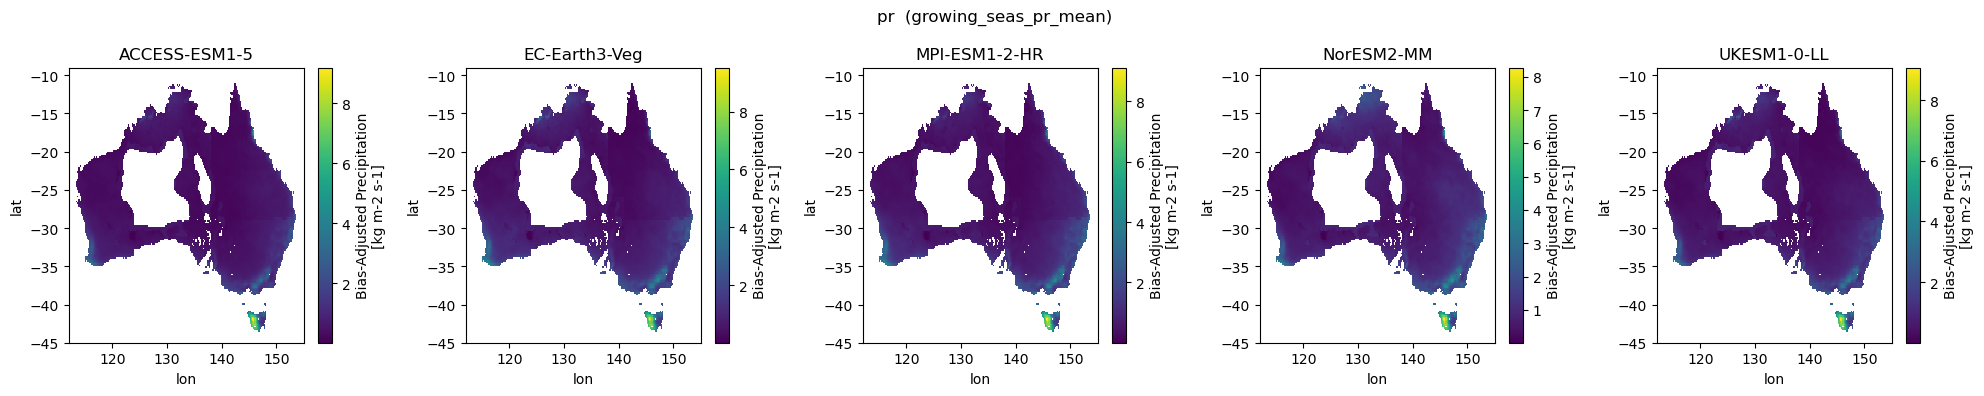

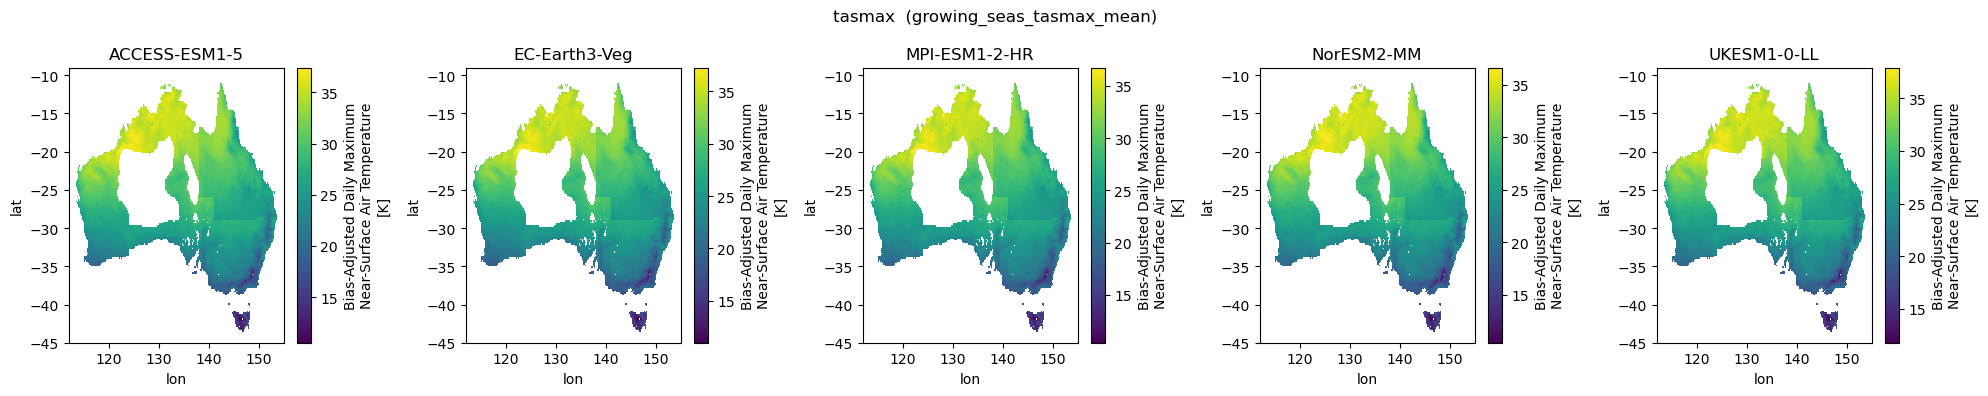

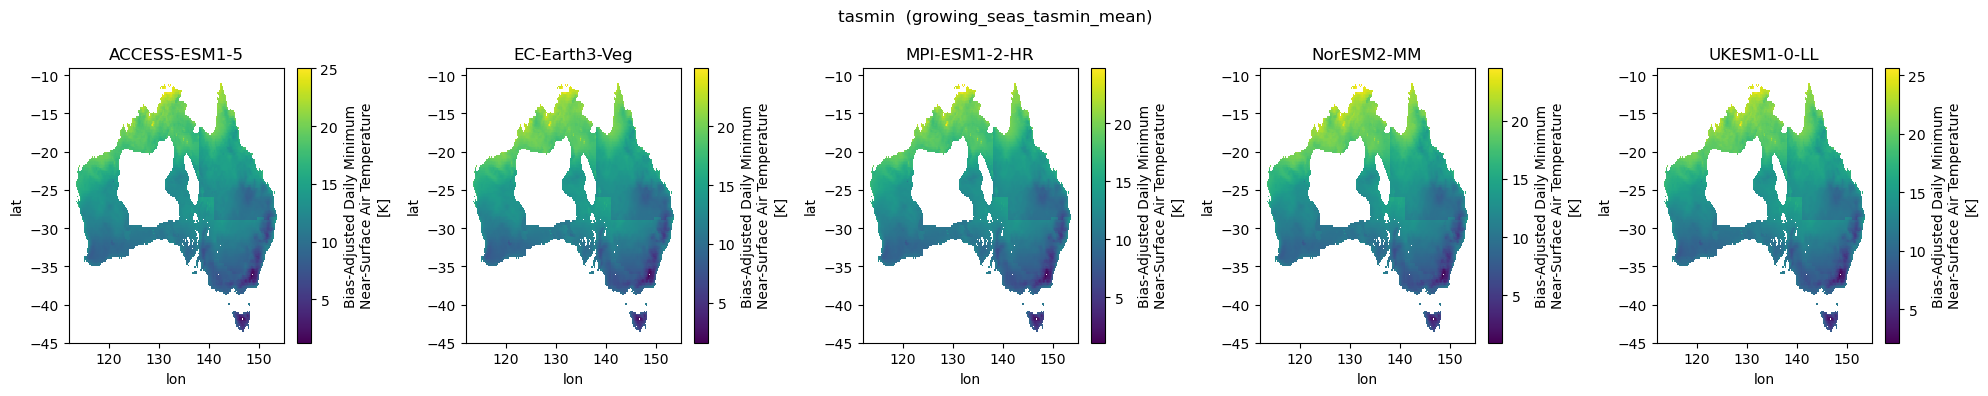

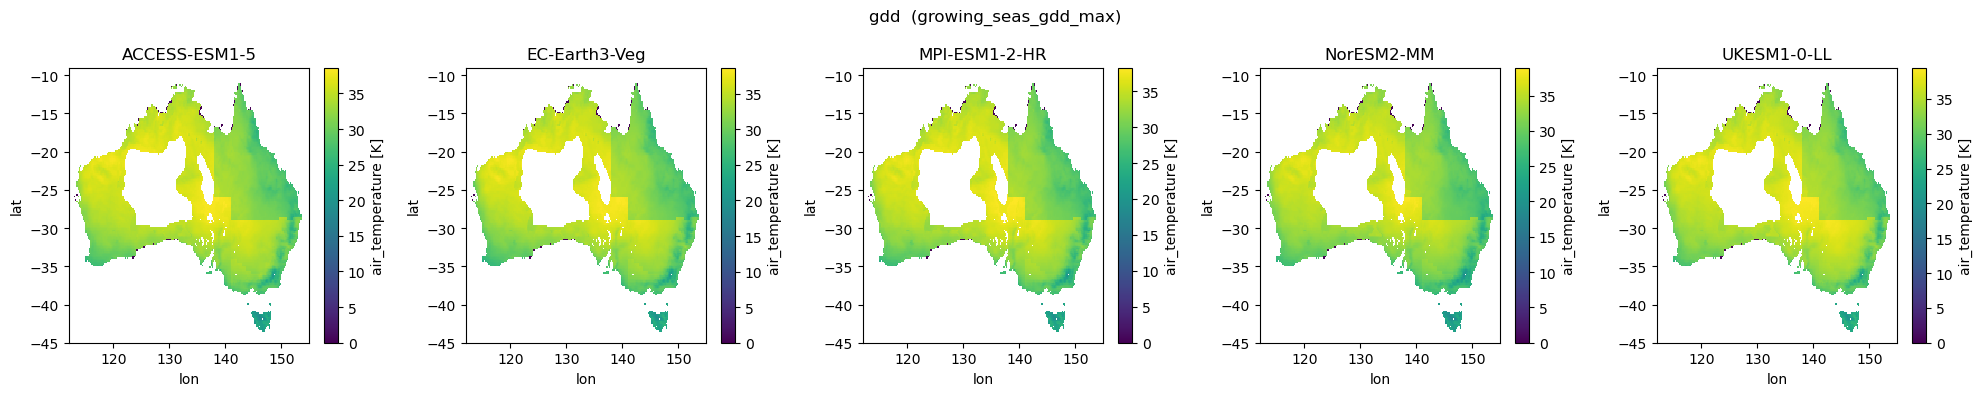

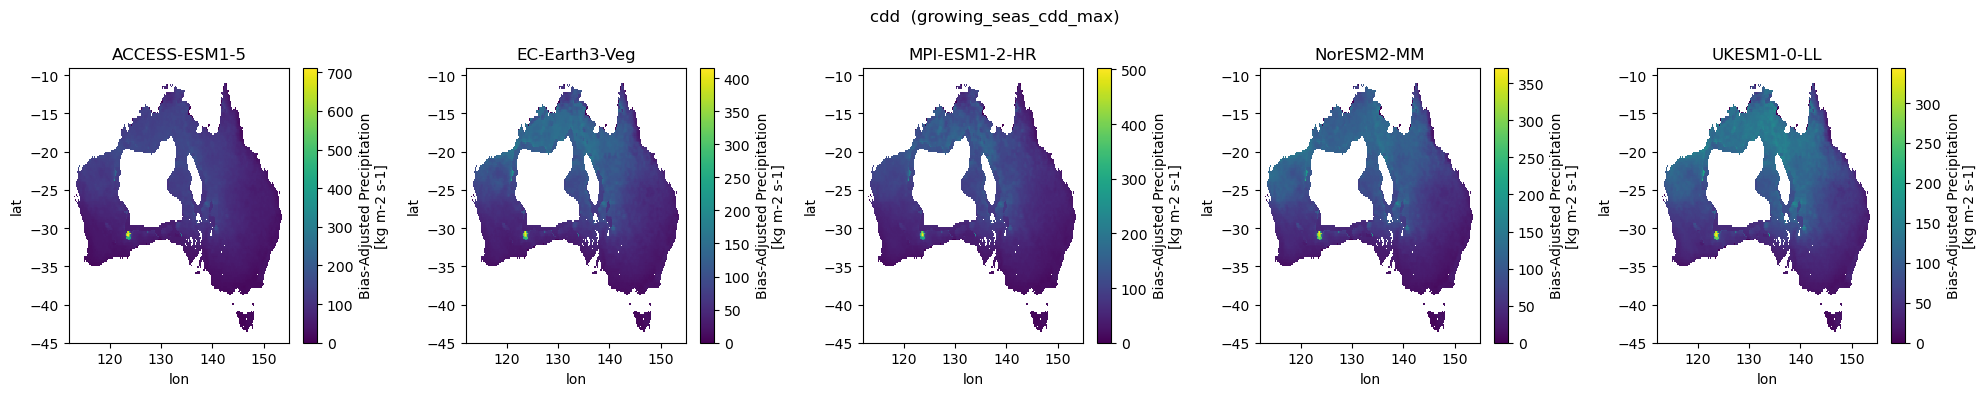

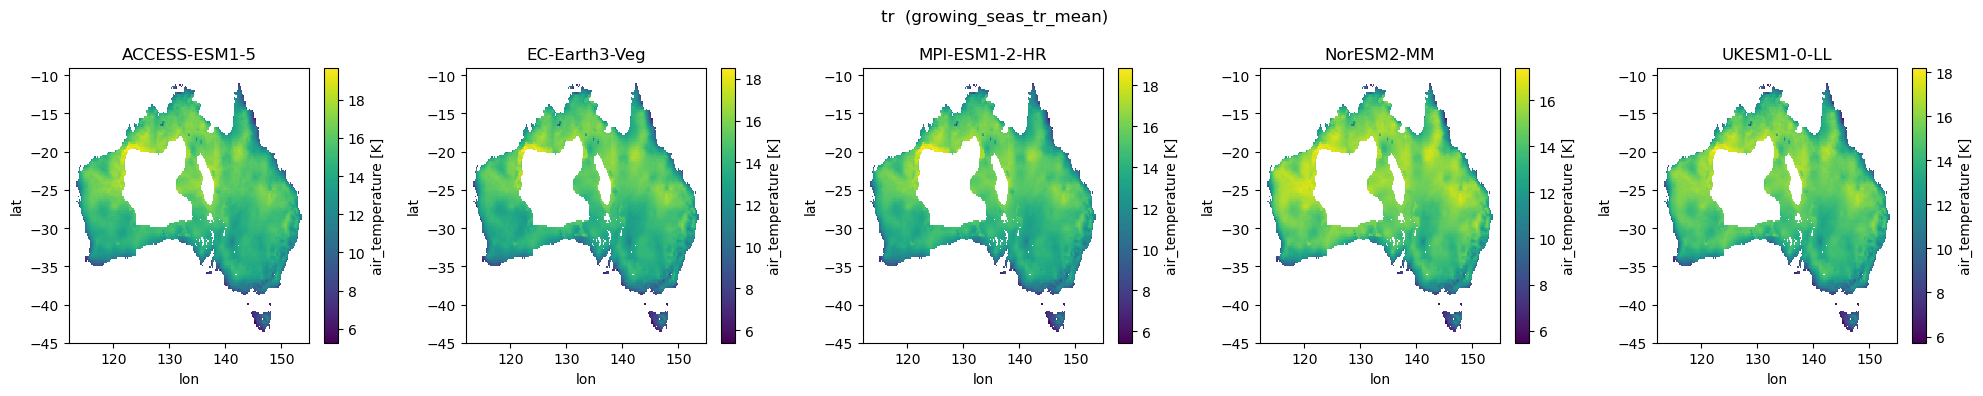

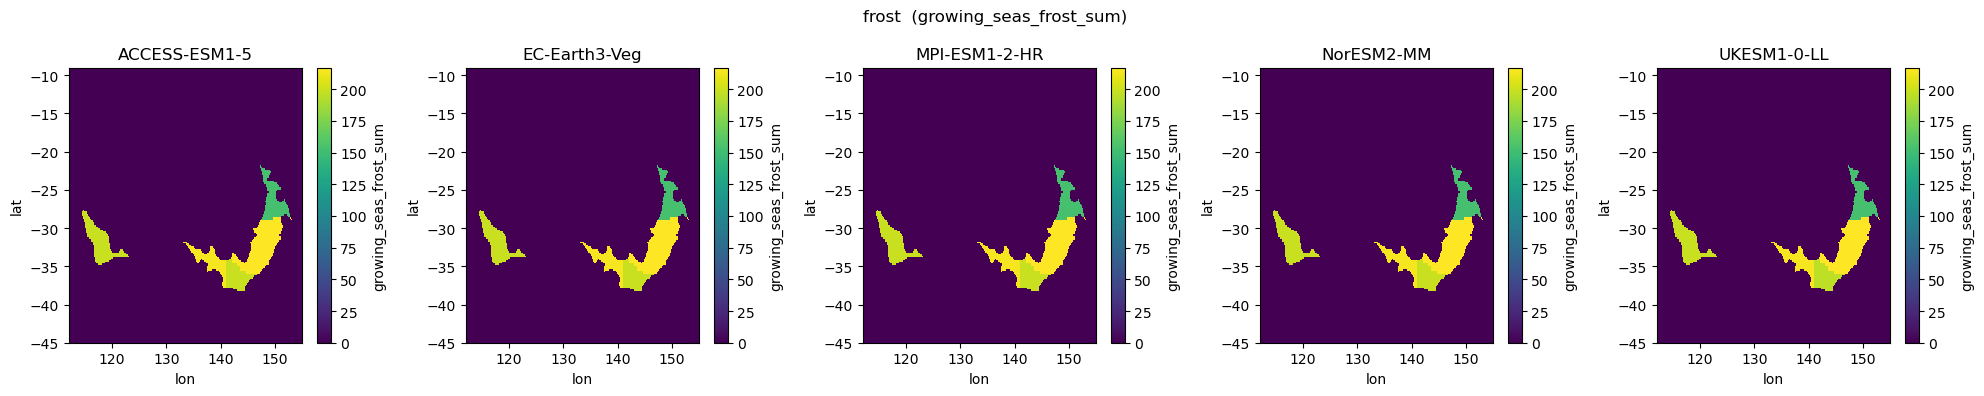

In [1]:
import glob
import os
import matplotlib.pyplot as plt
import xarray as xr

BASE = '/g/data/w97/mg5624/future_yield/NARCLIM_regrid/bias_adjusted/20km/ssp370'
RCM = 'NARCliM2-0-WRF412R3'
SCENARIO = 'ssp370'

# names as they appear in the file paths (not the in-file variable names)
VARS = ['pr_drought_180', 'pr_drought_180_int', 'pr_drought_30', 'pr_drought_30_int',
        'heatwave', 'heatwave_int', 'pr', 'tasmax', 'tasmin', 'gdd', 'cdd', 'tr', 'frost']


def get_growing_da(ds):
    """The single growing_seas_* variable in a model file (handles int/intensity naming)."""
    names = [v for v in ds.data_vars if v.startswith('growing_seas_')]
    if len(names) != 1:
        raise KeyError(f"Expected one growing_seas_* var, found {names}")
    return ds[names[0]], names[0]


for var in VARS:
    var_dir = f'{BASE}/{var}_FY'
    if not os.path.isdir(var_dir):
        print(f"{var}: no directory {var_dir}")
        continue

    models = sorted(os.listdir(var_dir))
    fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4), squeeze=False)
    da_name = None

    for ax, model in zip(axes[0], models):
        # '*' matches the realisation folder and the realisation part of the filename
        files = glob.glob(f'{var_dir}/{model}/{RCM}/*/{SCENARIO}_{model}_{RCM}_*_{var}_FY.nc')
        if len(files) != 1:
            print(f"{var} | {model}: expected 1 file, found {files}")
            ax.set_title(f"{model}\n(no file)")
            continue

        with xr.open_dataset(files[0]) as ds:
            da, da_name = get_growing_da(ds)
            da.mean(dim='time').plot(ax=ax)
        ax.set_title(model)

    fig.suptitle(f"{var}  ({da_name})")
    plt.tight_layout()
    fig.savefig(f'plot_first_timestep_{var}.png', dpi=150)
    plt.show()

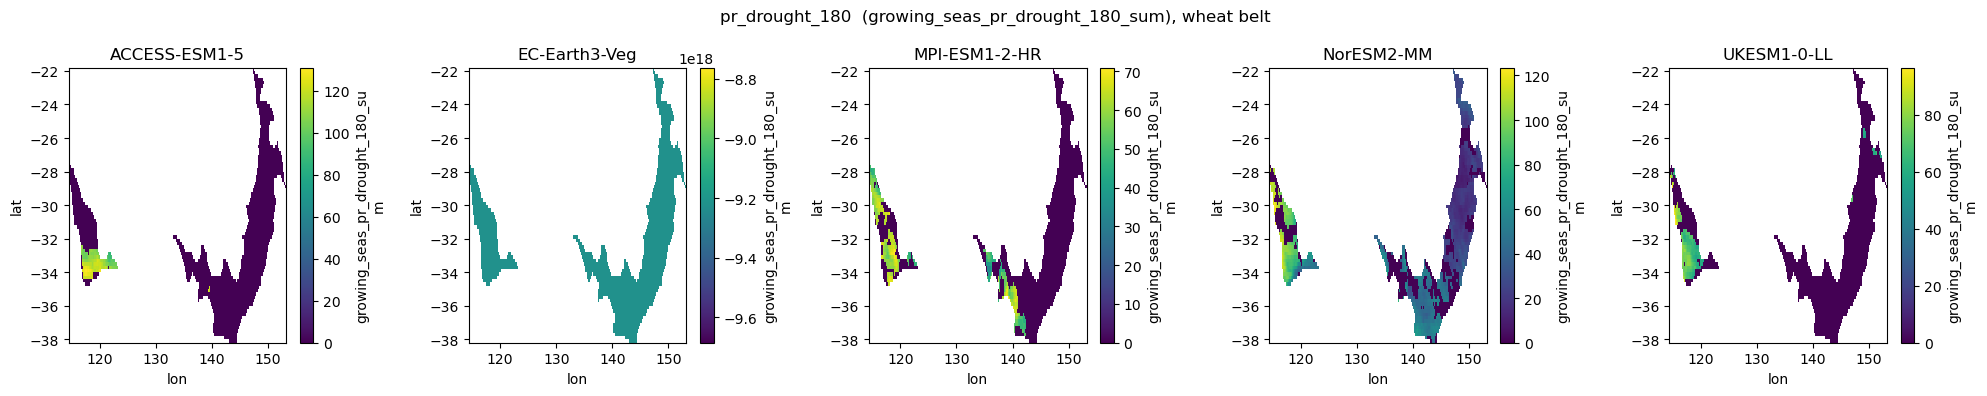

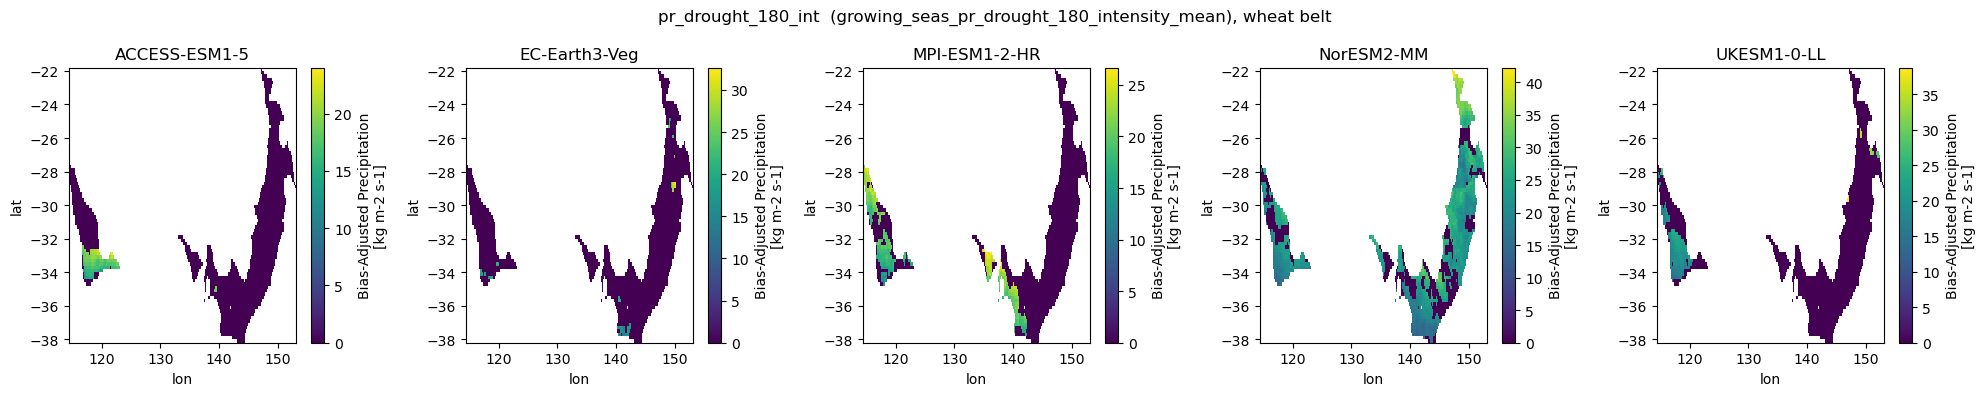

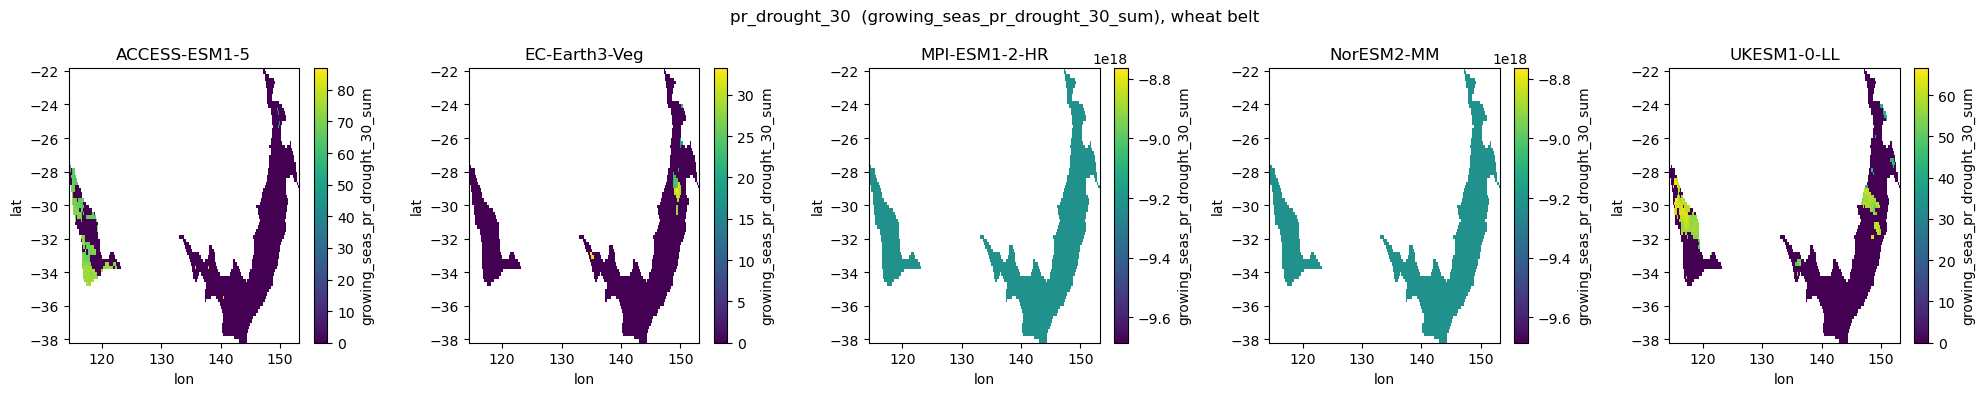

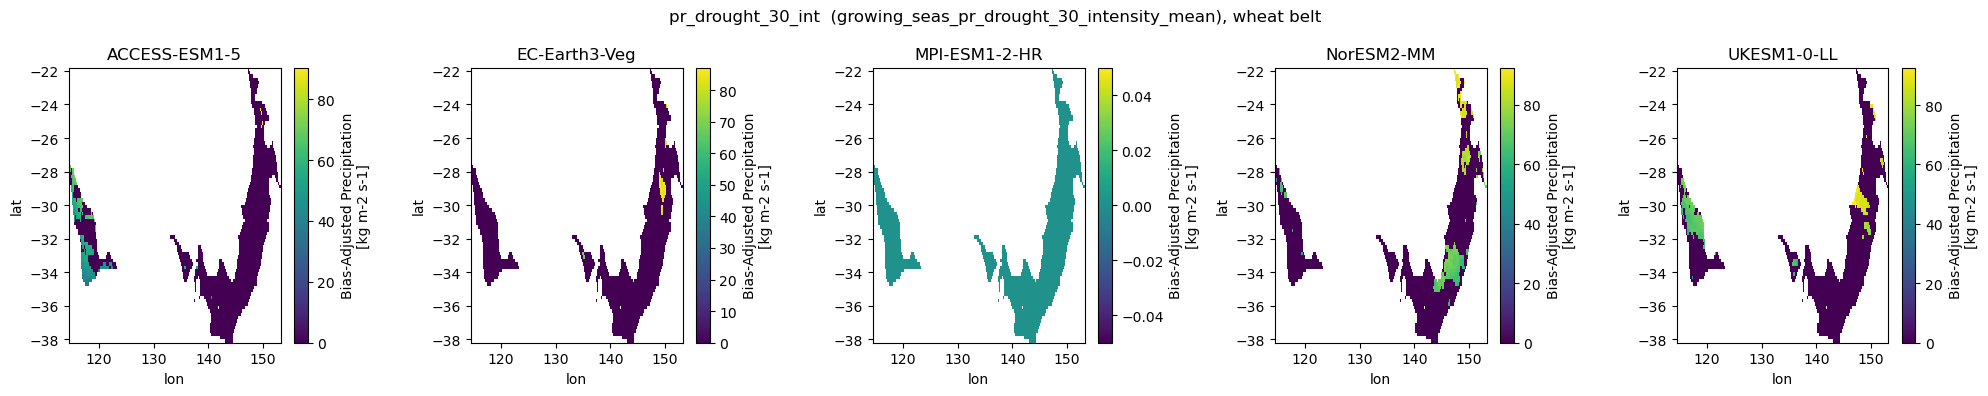

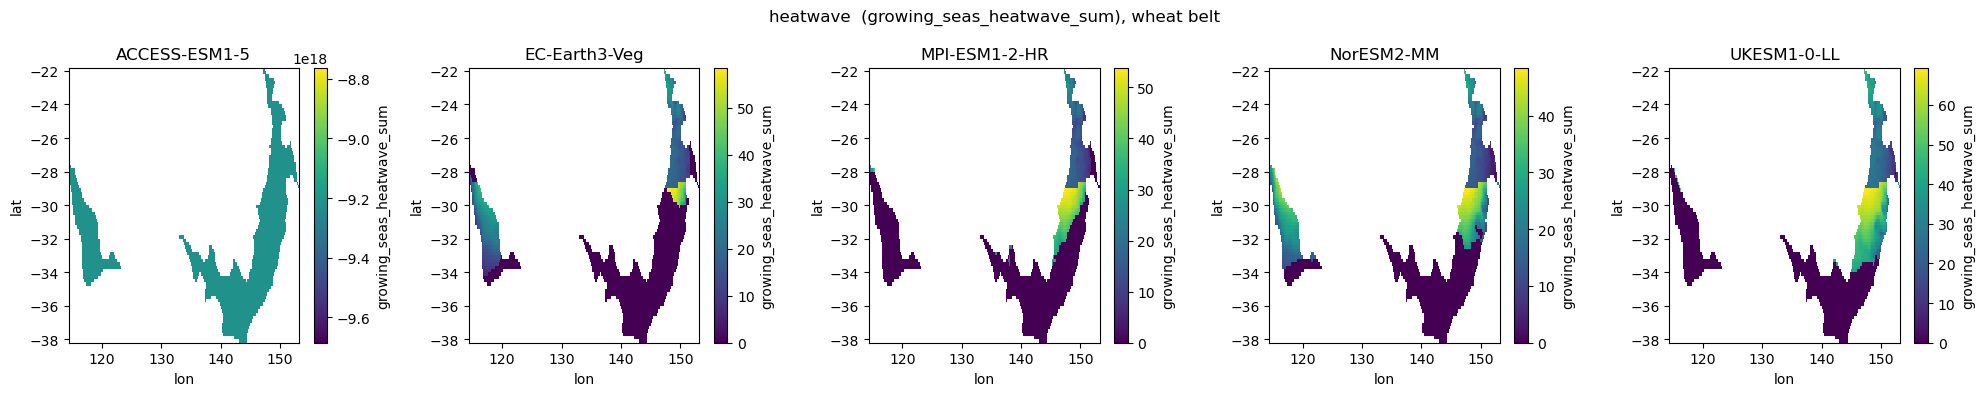

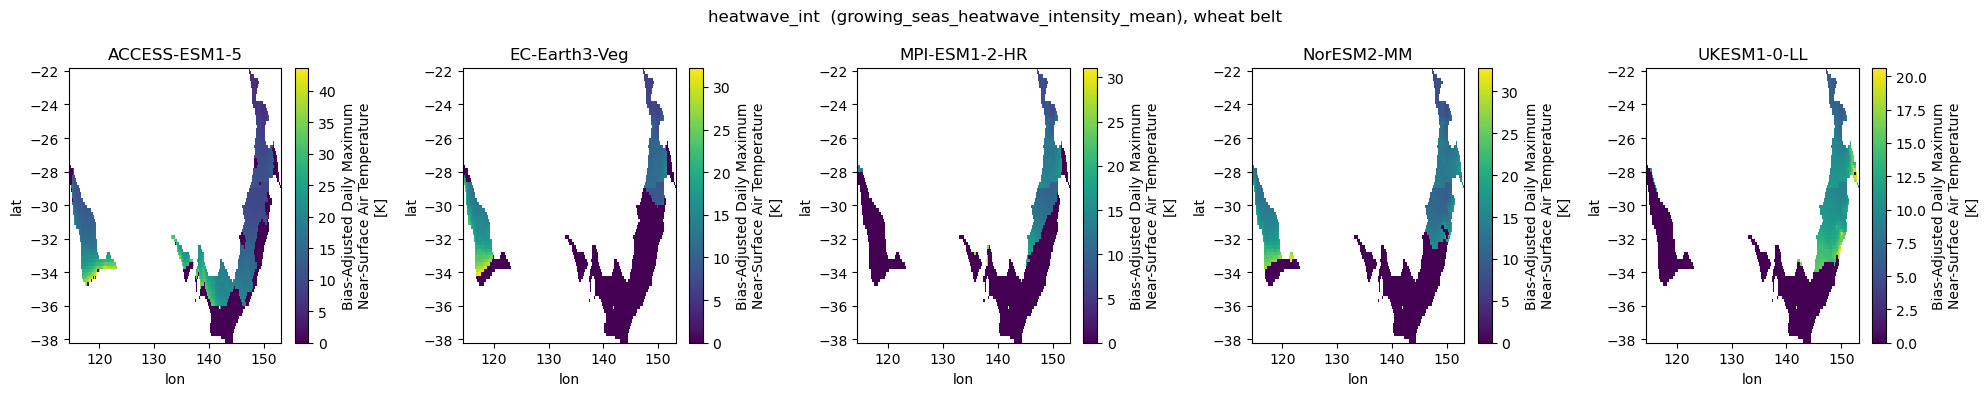

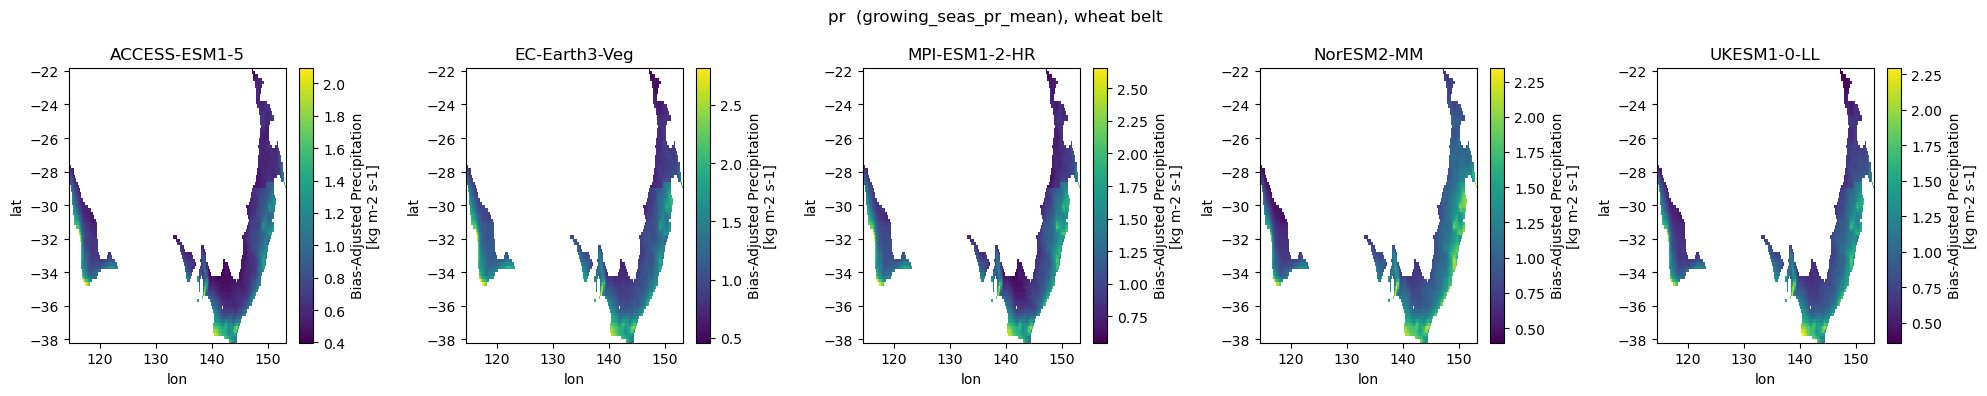

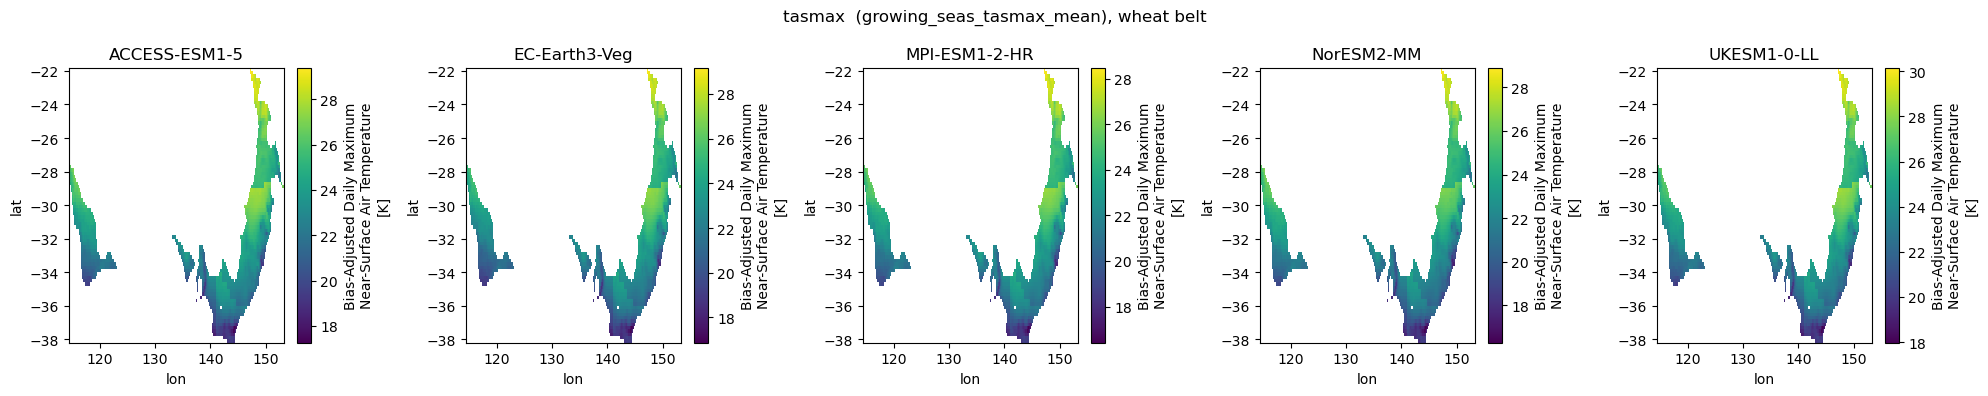

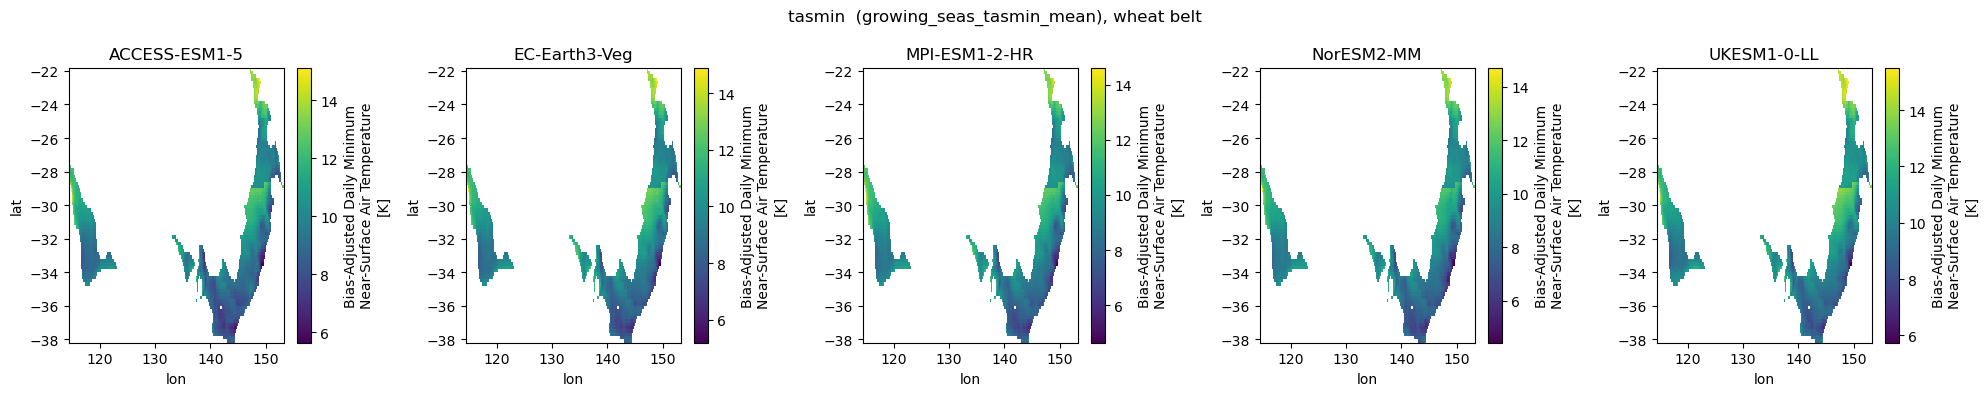

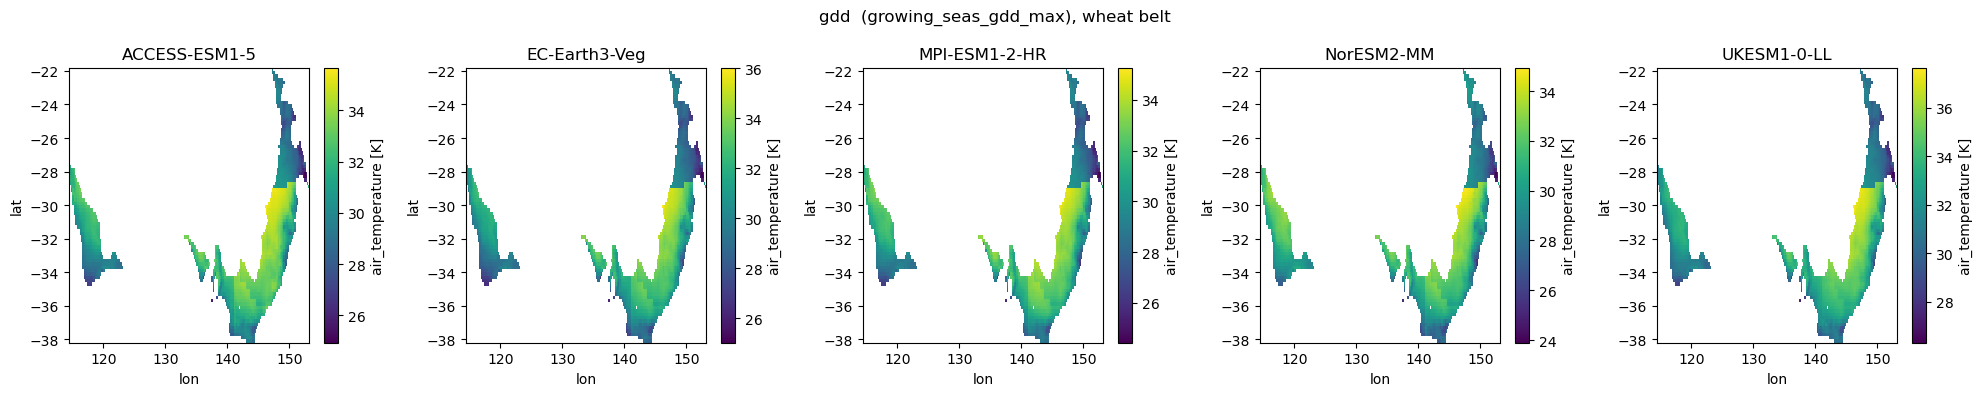

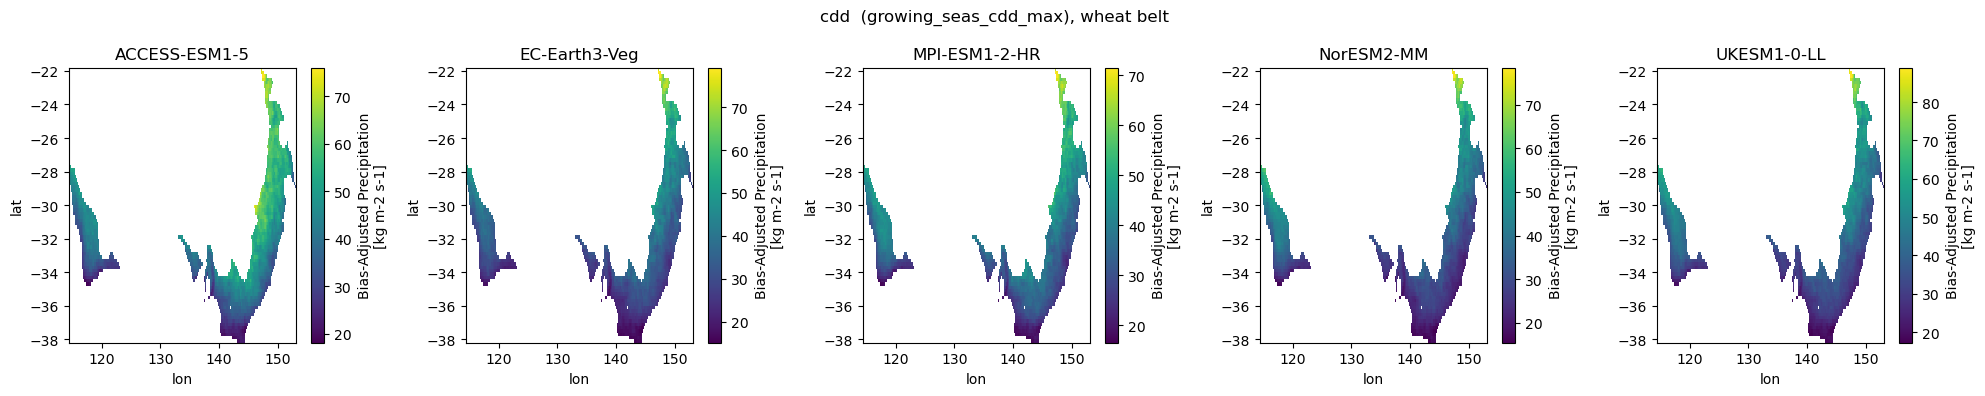

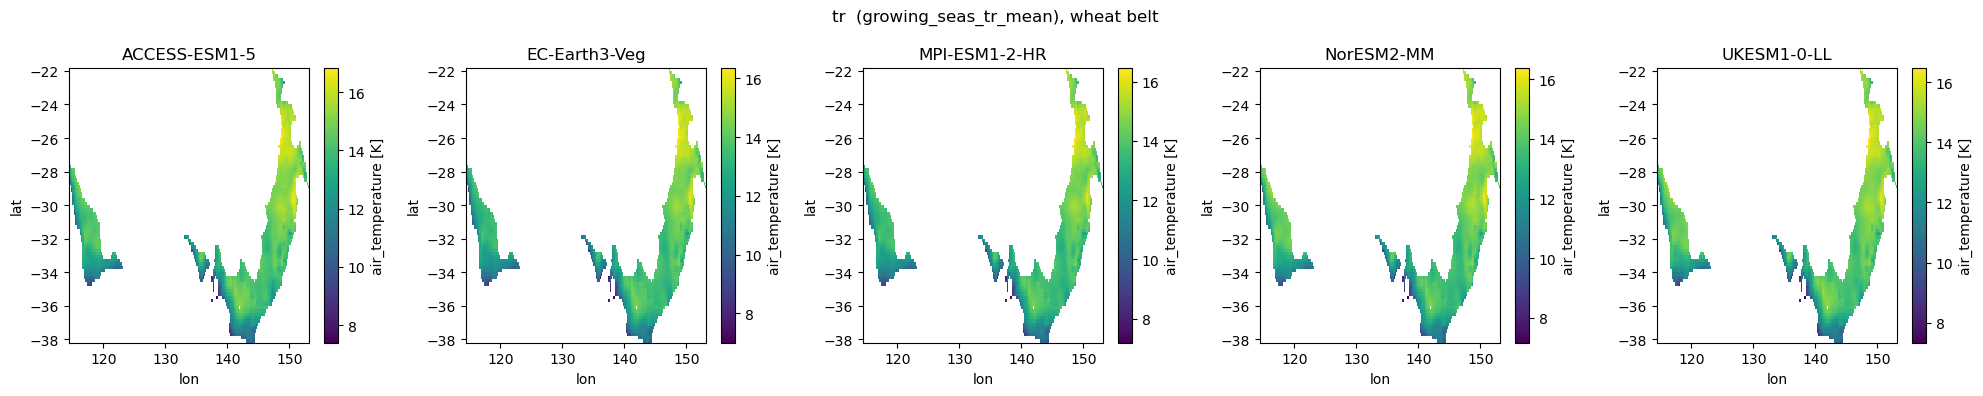

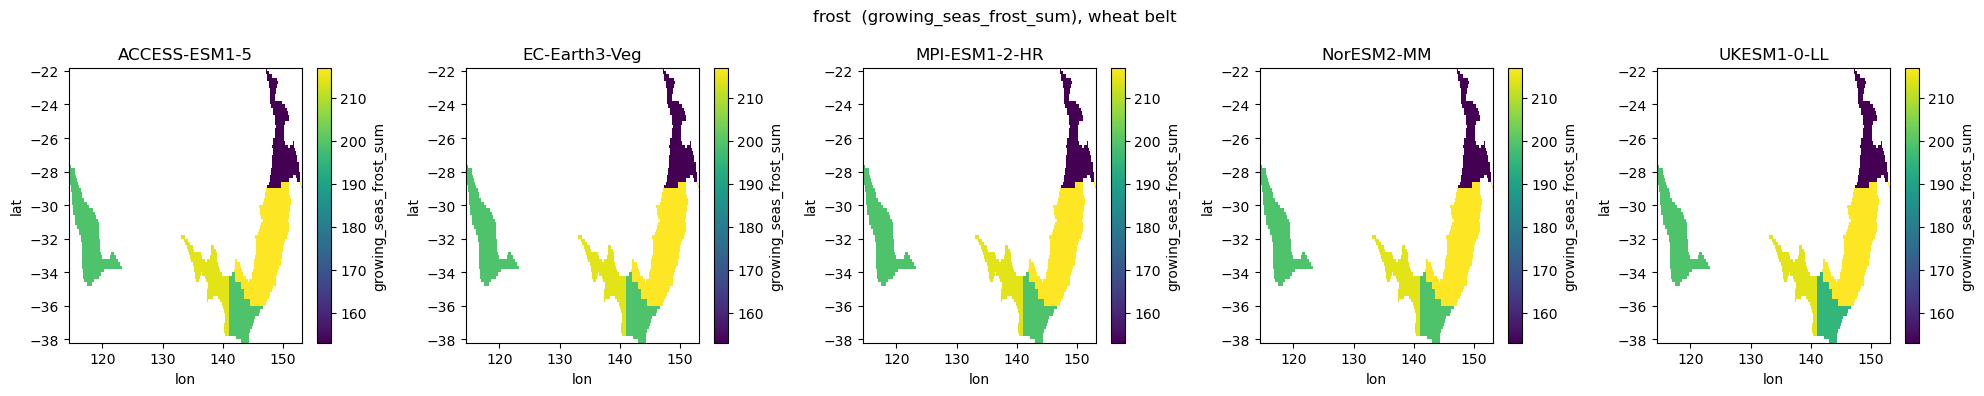

In [2]:
import glob
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

BASE = '/g/data/w97/mg5624/future_yield/NARCLIM_regrid/bias_adjusted/20km/ssp370'
RCM = 'NARCliM2-0-WRF412R3'
SCENARIO = 'ssp370'
WHEAT_BELT_MASK_FILE = "/g/data/w97/mg5624/ABS_project/ag_data/wheatbelt_shapefiles/wheatbelt.nc"

VARS = ['pr_drought_180', 'pr_drought_180_int', 'pr_drought_30', 'pr_drought_30_int',
        'heatwave', 'heatwave_int', 'pr', 'tasmax', 'tasmin', 'gdd', 'cdd', 'tr', 'frost']

wheat_mask = xr.open_dataarray(WHEAT_BELT_MASK_FILE).load()


def regrid_mask(mask, target_grid):
    mask = mask.sortby("lat").astype(int)
    regridded = mask.interp_like(target_grid, method="nearest")
    inside = ((target_grid.lat >= float(mask.lat.min())) & (target_grid.lat <= float(mask.lat.max())) &
              (target_grid.lon >= float(mask.lon.min())) & (target_grid.lon <= float(mask.lon.max())))
    return regridded.where(inside, 0).astype(bool)


def get_growing_da(ds):
    names = [v for v in ds.data_vars if v.startswith('growing_seas_')]
    if len(names) != 1:
        raise KeyError(f"Expected one growing_seas_* var, found {names}")
    return ds[names[0]], names[0]


def belt_mean(da):
    """Time mean, masked to the wheat belt and cropped to its bounding box."""
    belt = regrid_mask(wheat_mask, da.isel(time=0).reset_coords(drop=True)).reset_coords(drop=True)
    mean = da.mean(dim='time').where(belt)
    rows = np.flatnonzero(belt.any('lon').values)
    cols = np.flatnonzero(belt.any('lat').values)
    return mean.isel(lat=slice(rows[0], rows[-1] + 1), lon=slice(cols[0], cols[-1] + 1))


for var in VARS:
    var_dir = f'{BASE}/{var}_FY'
    if not os.path.isdir(var_dir):
        print(f"{var}: no directory {var_dir}")
        continue

    models = sorted(os.listdir(var_dir))
    fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4), squeeze=False)
    da_name = None

    for ax, model in zip(axes[0], models):
        files = glob.glob(f'{var_dir}/{model}/{RCM}/*/{SCENARIO}_{model}_{RCM}_*_{var}_FY.nc')
        if len(files) != 1:
            print(f"{var} | {model}: expected 1 file, found {files}")
            ax.set_title(f"{model}\n(no file)")
            continue

        with xr.open_dataset(files[0]) as ds:
            da, da_name = get_growing_da(ds)
            belt_mean(da).plot(ax=ax)
        ax.set_title(model)

    fig.suptitle(f"{var}  ({da_name}), wheat belt")
    plt.tight_layout()
    plt.show()

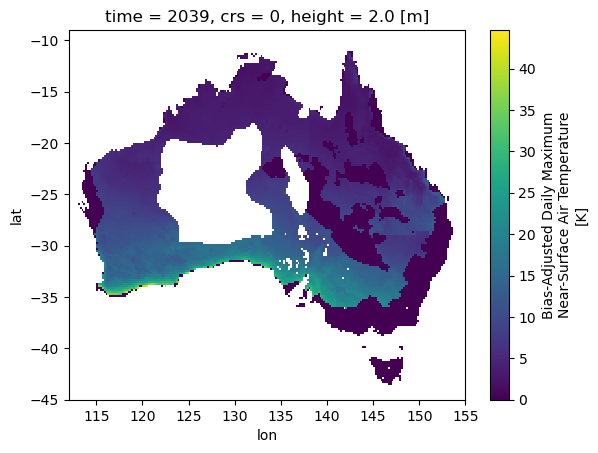

In [4]:
ds.growing_seas_heatwave_intensity_mean.isel(time=23).plot()

In [5]:
import xarray as xr
path = '/g/data/w97/mg5624/future_yield/NARCLIM_regrid/bias_adjusted/20km/ssp370/heatwave_FY/ACCESS-ESM1-5/NARCliM2-0-WRF412R3/r6i1p1f1/'
file = 'ssp370_ACCESS-ESM1-5_NARCliM2-0-WRF412R3_r6i1p1f1_heatwave_FY.nc'

ds = xr.open_dataset(path+file)
ds

<xarray.Dataset> Size: 105MB
Dimensions:                     (time: 85, lat: 180, lon: 215)
Coordinates:
  * time                        (time) int64 680B 2016 2017 2018 ... 2099 2100
  * lat                         (lat) float64 1kB -44.9 -44.7 ... -9.3 -9.1
  * lon                         (lon) float64 2kB 112.1 112.3 ... 154.7 154.9
Data variables:
    growing_seas_heatwave_sum   (time, lat, lon) int64 26MB ...
    planting_seas_heatwave_sum  (time, lat, lon) int64 26MB ...
    mid_seas_heatwave_sum       (time, lat, lon) int64 26MB ...
    harvest_seas_heatwave_sum   (time, lat, lon) int64 26MB ...

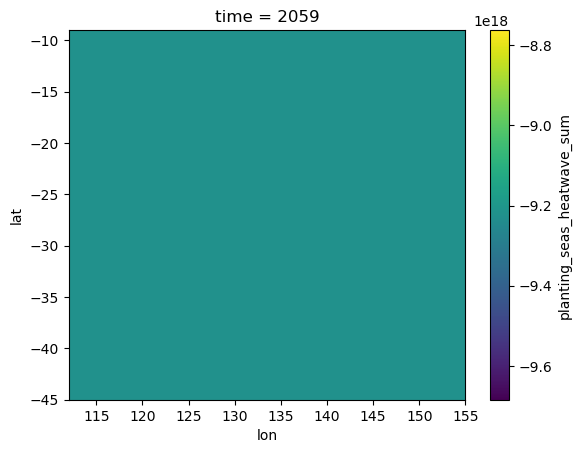

In [ ]:
ds.growing_seas_heatwave_sum.isel(time=43).plot()

In [ ]:
earlier_filename = 'heatwave_intensity_FY_agg_1950-2021.nc'
FY_path = '/g/data/w97/mg5624/ABS_project/extremes/FY_aggregated/'
earlier_da = xr.open_dataset(FY_path+earlier_filename)
earlier_gs_hw = earlier_da.growing_seas_heatwave_intensity_mean
earlier_gs_hw

NameError: name 'xr' is not defined

In [2]:
import pandas as pd

abares_path = '/g/data/w97/mg5624/ABS_project/ABARES/fdp-regional-historical.csv'
abares = pd.read_csv(abares_path)
abares

,Variable,Year,ABARES region,Value,RSE
0,AI stud fees and herd testing ($),1990,NSW Central West,90.0,68.0
1,Accounting services ($),1990,NSW Central West,2480.0,19.0
2,Advisory services ($),1990,NSW Central West,120.0,80.0
3,Age of owner manager (yrs),1990,NSW Central West,57.0,5.0
4,Age of spouse (yrs),1990,NSW Central West,51.0,4.0
...,...,...,...,...,...
146507,Wheat produced (t),2023,WA The Kimberley,0.0,NaN
146508,Wheat receipts ($),2023,WA The Kimberley,0.0,NaN
146509,Wheat sold (t),2023,WA The Kimberley,0.0,NaN
146510,Wool produced (kg),2023,WA The Kimberley,0.0,NaN


In [ ]:
path = '/scratch/w97/mg5624/extremes/daily/'
file1 = '180_ag_drought_1950-2021_1.nc'
file2 = '180_ag_drought_1950-2021_2.nc'

da1 = xr.open_dataset(path + file1)
da2 = xr.open_dataset(path + file2)



In [4]:
import xarray as xr

def main():
    drought_days = 180
    var_name = f'{drought_days}_ag_drought_1950-2021'
    path = '/scratch/w97/mg5624/extremes/daily/'
    ds1 = xr.open_dataset(path + f'{var_name}_1.nc')
    ds2 = xr.open_dataset(path + f'{var_name}_2.nc')
    ds2 = ds2.sel(lon=ds2.lon < 135)

    combined_ds = xr.combine_by_coords([ds1, ds2], combine_attrs='override')
    var_name_out = f'{drought_days}_ag_drought_extremes_1950-2021'
    combined_ds.to_netcdf(path + f'{var_name_out}.nc')


if __name__ == '__main__':
    main()

: 

In [7]:
import xarray as xr
file = 'precip_FY_agg_1950-2021.nc'
path = '/g/data/w97/mg5624/ABS_project/extremes/FY_aggregated/'
ds = xr.open_dataset(path + file)
ds

<xarray.Dataset> Size: 695MB
Dimensions:                    (time: 71, lat: 691, lon: 886)
Coordinates:
  * time                       (time) int64 568B 1951 1952 1953 ... 2020 2021
  * lat                        (lat) float32 3kB -44.5 -44.45 ... -10.05 -10.0
  * lon                        (lon) float32 4kB 112.0 112.1 ... 156.2 156.2
Data variables:
    growing_seas_precip_mean   (time, lat, lon) float32 174MB ...
    planting_seas_precip_mean  (time, lat, lon) float32 174MB ...
    mid_seas_precip_mean       (time, lat, lon) float32 174MB ...
    harvest_seas_precip_mean   (time, lat, lon) float32 174MB ...

In [2]:
import pandas as pd

In [7]:
datadir = '/g/data/w97/mg5624/ABS_project/'
perf_datadir = f'{datadir}/yield_model_analytics/performance_scores/'
states = ['AUS']#, 'NSW', 'VIC', 'QLD', 'SA', 'WA']
for state in states:
    state_yield = pd.read_csv(
        f'{perf_datadir}/state_aggregated/all_temp_and_hyd/full_season_only/single_drought_180/RandomForestRegressor_{state}_predicted_vs_true_yield_yearsplit_20agland_norm.csv',
        index_col=0
    )
    df0 = state_yield[state_yield["seed"] == 0].sort_values("year")
    # print(df0)
    df0_mean_true = df0.mean()
    print(df0_mean_true)

year         2010.500000
True           -0.016984
Predicted      -0.029213
seed            0.000000
dtype: float64


In [3]:
import xarray as xr
filename = '30_day_precip_drought_FY_antecedent_agg_1950-2021.nc'
filepath = '/g/data/w97/mg5624/ABS_project/extremes/FY_aggregated/'
ds = xr.open_dataarray(filepath + filename)
ds

<xarray.DataArray '30_day_precip_drought' (time: 72, lat: 691, lon: 886)> Size: 353MB
[44080272 values with dtype=int64]
Coordinates:
  * time     (time) int64 576B 1951 1952 1953 1954 1955 ... 2019 2020 2021 2022
  * lat      (lat) float32 3kB -44.5 -44.45 -44.4 -44.35 ... -10.1 -10.05 -10.0
  * lon      (lon) float32 4kB 112.0 112.1 112.1 112.2 ... 156.1 156.2 156.2